# Project 03 — Four Linear Algebra Methods

## Notebook 02 — Principal Component Analysis (PCA)

**Blocks:** 06–10  
**Dataset:** 400 MRI images; 128 × 128 grayscale; 16,384 features per image  
**Main project directory (Google Colab):** `MyDrive/MATHEMATICS_PROJECTS/PROJECT_03_LA_ML_FOUR_METHODS/`  
**Processed files:** `data/processed/X_mri_400.npy`, `y_mri_400.npy`, `filenames_mri_400.json`

*Execution note: Run cells in order after mounting Google Drive. Notebook 01 creates the processed dataset used by the following notebooks.*


### Mathematical purpose and interpretation

Principal Component Analysis (PCA) analyzes variability **after subtracting the feature-wise mean**. It identifies orthogonal directions of maximum sample variance, ordered by their explained-variance ratios. Here, the first ten components explain approximately **50.53%** of the centered matrix's total variance.

The minimum component counts for **90%, 95%, and 99% explained variance** are **142, 210, and 323**, respectively. Greater retention generally reduces the in-sample reconstruction error: approximately **0.3161, 0.2225, and 0.0990** for these three targets. These are reconstruction measurements, **not** classification accuracy or evidence of diagnostic performance. The results describe the particular 400-image sample and preprocessing pipeline.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Block 06 — PCA Dataset Loading and Verification


In [2]:

from pathlib import Path
import numpy as np
import json

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "MATHEMATICS_PROJECTS/"
    "PROJECT_03_LA_ML_FOUR_METHODS"
)

DATA_DIR = PROJECT_ROOT / "data/processed"

# Load the processed data
X = np.load(DATA_DIR / "X_mri_400.npy")
y = np.load(DATA_DIR / "y_mri_400.npy")

with open(DATA_DIR / "filenames_mri_400.json", "r") as f:
    filenames = json.load(f)

# Dataset information
n, p = X.shape

print("BLOCK 06 — PCA DATASET VERIFICATION")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X dtype:", X.dtype)
print("Number of filenames:", len(filenames))

print("\nPIXEL INTENSITIES")
print("Minimum:", X.min())
print("Maximum:", X.max())

print("\nCLASS DISTRIBUTION")
classes = ["glioma", "meningioma", "notumor", "pituitary"]

for i, category in enumerate(classes):
    print(f"{category}: {np.sum(y == i)}")

# Numerical verification
checks_passed = (
    X.shape == (400, 16384)
    and y.shape == (400,)
    and X.dtype == np.float32
    and len(filenames) == 400
    and np.isfinite(X).all()
    and X.min() >= 0
    and X.max() <= 1
    and all(np.sum(y == i) == 100 for i in range(4))
)

assert checks_passed, "Block 06 verification failed."

print("\nALL BLOCK 06 CHECKS PASSED:", checks_passed)


BLOCK 06 — PCA DATASET VERIFICATION
X shape: (400, 16384)
y shape: (400,)
X dtype: float32
Number of filenames: 400

PIXEL INTENSITIES
Minimum: 0.0
Maximum: 1.0

CLASS DISTRIBUTION
glioma: 100
meningioma: 100
notumor: 100
pituitary: 100

ALL BLOCK 06 CHECKS PASSED: True


## Block 07 — Mean Vector, Centering, and Variance


In [3]:
import numpy as np

# Use float64 for more accurate numerical verification
X64 = X.astype(np.float64)

n, p = X64.shape

# Mean vector
mu = X64.mean(axis=0)

# Centered matrix
Xc = X64 - mu

# Sample variance per feature
feature_variance = Xc.var(axis=0, ddof=1)

# Verify centering
centered_column_means = Xc.mean(axis=0)
max_centering_error = np.max(np.abs(centered_column_means))

# Summary statistics
print("BLOCK 07 — PCA CENTERING AND VARIANCE")

print("\nMATRIX DIMENSIONS")
print("X shape:", X64.shape)
print("Mean vector shape:", mu.shape)
print("Centered matrix shape:", Xc.shape)
print("Variance vector shape:", feature_variance.shape)

print("\nMEAN VECTOR")
print("Minimum mean intensity:", mu.min())
print("Maximum mean intensity:", mu.max())
print("Mean vector norm:", np.linalg.norm(mu))

print("\nCENTERING VERIFICATION")
print("Maximum absolute column mean:", max_centering_error)

print("\nFEATURE VARIANCE")
print("Minimum variance:", feature_variance.min())
print("Maximum variance:", feature_variance.max())
print("Average variance:", feature_variance.mean())
print("Zero-variance features:", np.sum(feature_variance == 0))

# Numerical checks
checks_passed = (
    mu.shape == (16384,)
    and Xc.shape == (400, 16384)
    and feature_variance.shape == (16384,)
    and np.isfinite(mu).all()
    and np.isfinite(Xc).all()
    and np.isfinite(feature_variance).all()
    and np.all(feature_variance >= 0)
    and max_centering_error < 1e-12
)

print("\nALL BLOCK 07 CHECKS PASSED:", checks_passed)

BLOCK 07 — PCA CENTERING AND VARIANCE

MATRIX DIMENSIONS
X shape: (400, 16384)
Mean vector shape: (16384,)
Centered matrix shape: (400, 16384)
Variance vector shape: (16384,)

MEAN VECTOR
Minimum mean intensity: 0.009754902346758172
Maximum mean intensity: 0.34040196975693104
Mean vector norm: 27.967246636507543

CENTERING VERIFICATION
Maximum absolute column mean: 5.331846075762315e-16

FEATURE VARIANCE
Minimum variance: 0.0004703863058578384
Maximum variance: 0.06082392837117878
Average variance: 0.025239036753947723
Zero-variance features: 0

ALL BLOCK 07 CHECKS PASSED: True



### PROJECT 03 — BLOCK 07: Mean Vector, Centering, and Variance Analysis

**Objective:** Calculate the mean vector, center the MRI data matrix, and analyze feature variance before applying PCA.

### 1. Original Data Matrix

Our dataset contains 400 MRI images, each represented by 16,384 pixel intensities.

$$
X \in \mathbb{R}^{400 \times 16384}
$$

Each row represents an MRI image, and each column represents a pixel position (feature).

### 2. Mean Vector

We calculate the mean of each feature:

$$
\mu_j = \frac{1}{400}\sum_{i=1}^{400}X_{ij}
$$

Therefore, the mean is a vector:

$$
\mu = (\mu_1,\mu_2,\ldots,\mu_{16384})
$$

$$
\mu \in \mathbb{R}^{16384}
$$

**Why is μ a vector?**

PCA requires the mean of each feature, not just one global mean. Since our images have 16,384 pixels, we need 16,384 individual means.

### 3. Mean Vector — Numerical Results

- Minimum component of μ: 0.00975490
- Maximum component of μ: 0.34040197
- Euclidean norm of μ: 27.96724664
- Global mean pixel intensity: 0.18548435

The Euclidean norm is:

$$
\|\mu\|_2 = \sqrt{\sum_{j=1}^{16384}\mu_j^2}
$$

The global mean is a scalar:

$$
\bar{x}=\frac{1}{400\cdot16384}
\sum_{i=1}^{400}\sum_{j=1}^{16384}X_{ij}
$$

The mean vector and global mean are different mathematical objects.

### 4. Centered Matrix

We subtract the corresponding feature mean from every observation:

$$
X_c = X-\mathbf{1}\mu^T
$$

Equivalently:

$$
(X_c)_{ij}=X_{ij}-\mu_j
$$

The centered matrix has dimensions:

$$
X_c \in \mathbb{R}^{400 \times 16384}
$$

After centering, each column should have mean approximately zero.

**Numerical verification:**

Maximum absolute column mean:

$$
5.3318461 \times 10^{-16}
$$

This value is approximately zero, confirming successful centering.

### 5. Feature Variance

The sample variance of feature j is:

$$
s_j^2=\frac{1}{399}\sum_{i=1}^{400}(X_{ij}-\mu_j)^2
$$

The variance vector contains 16,384 values:

$$
s^2 \in \mathbb{R}^{16384}
$$

**Numerical results:**

- Minimum variance: 0.0004703863
- Maximum variance: 0.0608239284
- Average variance: 0.0252390368
- Zero-variance features: 0

Every feature exhibits some variation across the 400 MRI images.

### 6. Mathematical Verification

| Mathematical object | Dimensions |
|---|---|
| Original matrix X | 400 × 16,384 |
| Mean vector μ | 16,384 |
| Centered matrix Xc | 400 × 16,384 |
| Variance vector | 16,384 |

**Verification result:**

ALL BLOCK 07 CHECKS PASSED: True

### 7. Mathematical Conclusion

PCA analyzes variation around the mean of each feature.

Because each pixel position has its own mean, we calculate a mean vector instead of a single scalar.

Centering produces a matrix whose columns have approximately zero mean.

The resulting centered matrix is ready for Principal Component Analysis.

**Next:** Block 08 — PCA and Explained Variance.


## Block 08 — PCA and Explained Variance


In [4]:
import numpy as np

print("BLOCK 08 — PCA AND EXPLAINED VARIANCE")

# Centered data from Block 07
n, p = Xc.shape

# Small Gram matrix
G = (Xc @ Xc.T) / (n - 1)

print("\nMATRIX DIMENSIONS")
print("Centered matrix:", Xc.shape)
print("Gram matrix:", G.shape)

# Eigendecomposition of the symmetric Gram matrix
eigenvalues, eigenvectors = np.linalg.eigh(G)

# Sort eigenvalues and eigenvectors in descending order
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Remove tiny negative eigenvalues caused by floating-point error
eigenvalues = np.maximum(eigenvalues, 0.0)

# Explained variance ratio
total_variance = np.sum(eigenvalues)
evr = eigenvalues / total_variance

# Cumulative explained variance
cumulative_evr = np.cumsum(evr)

print("\nTOP 10 PRINCIPAL COMPONENTS")

for i in range(10):
    print(
        f"PC{i+1}: "
        f"Eigenvalue = {eigenvalues[i]:.8f}, "
        f"EVR = {evr[i]*100:.4f}%, "
        f"Cumulative = {cumulative_evr[i]*100:.4f}%"
    )

print("\nVARIANCE VERIFICATION")
print("Total variance:", total_variance)
print("Sum of explained variance ratios:", evr.sum())

# Numerical verification
checks_passed = (
    G.shape == (400, 400)
    and np.all(np.isfinite(eigenvalues))
    and np.all(eigenvalues >= 0)
    and np.isclose(evr.sum(), 1.0, atol=1e-10)
    and np.all(np.diff(cumulative_evr) >= -1e-12)
    and np.isclose(
        total_variance,
        np.sum(Xc**2) / (n - 1),
        rtol=1e-10
    )
)

print("\nALL BLOCK 08 CHECKS PASSED:", checks_passed)

BLOCK 08 — PCA AND EXPLAINED VARIANCE

MATRIX DIMENSIONS
Centered matrix: (400, 16384)
Gram matrix: (400, 400)

TOP 10 PRINCIPAL COMPONENTS
PC1: Eigenvalue = 103.39680811, EVR = 25.0043%, Cumulative = 25.0043%
PC2: Eigenvalue = 43.13117618, EVR = 10.4303%, Cumulative = 35.4346%
PC3: Eigenvalue = 13.99832854, EVR = 3.3852%, Cumulative = 38.8198%
PC4: Eigenvalue = 12.29140862, EVR = 2.9724%, Cumulative = 41.7922%
PC5: Eigenvalue = 7.15042912, EVR = 1.7292%, Cumulative = 43.5214%
PC6: Eigenvalue = 6.87768565, EVR = 1.6632%, Cumulative = 45.1846%
PC7: Eigenvalue = 6.36251472, EVR = 1.5386%, Cumulative = 46.7233%
PC8: Eigenvalue = 5.78338766, EVR = 1.3986%, Cumulative = 48.1219%
PC9: Eigenvalue = 5.19604731, EVR = 1.2566%, Cumulative = 49.3784%
PC10: Eigenvalue = 4.75271444, EVR = 1.1493%, Cumulative = 50.5277%

VARIANCE VERIFICATION
Total variance: 413.5163781766795
Sum of explained variance ratios: 1.0

ALL BLOCK 08 CHECKS PASSED: True


## Block 08 — PCA and Explained Variance



### BLOCK 08 — PCA and Explained Variance

**Objective:** Identify the principal directions of variation in our 400 MRI images.

Our centered data matrix is:

$$
X_c \in \mathbb{R}^{400 \times 16384}
$$

Instead of constructing a large covariance matrix, we use the smaller Gram matrix:

$$
G = \frac{1}{399}X_cX_c^T
$$

$$
G \in \mathbb{R}^{400 \times 400}
$$

We calculate its eigenvalues to determine the explained variance ratio (EVR):

$$
EVR_i = \frac{\lambda_i}{\sum_j \lambda_j}
$$

**Numerical results:**

- PC1 explains 25.0043% of the total variance.
- PC1 + PC2 explain 35.4346%.
- The first 5 components explain 43.5214%.
- The first 10 components explain 50.5277%.
- Total variance: 413.51637818.
- Sum of explained variance ratios: 1.0.

**Verification:** ALL BLOCK 08 CHECKS PASSED: True.

**Conclusion:** The first 10 principal components preserve approximately 50.53% of the total variance. More components are necessary to reach higher variance-retention thresholds.


# ***2. Block 09 — Cumulative Explained Variance Graph***


### BLOCK 09 — Interpretation of the Cumulative Explained Variance Graph

**Objective:** Determine how many principal components are required to preserve 90%, 95%, and 99% of the total variance.

The cumulative explained variance for the first k components is:

$$
CEVR(k) = \sum_{i=1}^{k} EVR_i
$$

We select the minimum number of components satisfying:

$$
k_\alpha = \min\{k : CEVR(k) \geq \alpha\}
$$

where:

$$
\alpha \in \{0.90, 0.95, 0.99\}
$$

**Graph interpretation:**

- Horizontal axis: Number of principal components.
- Vertical axis: Cumulative explained variance (%).
- Increasing curve: Percentage of variance preserved as more components are included.
- Horizontal dashed lines: Variance-retention thresholds of 90%, 95%, and 99%.

The intersection of the cumulative variance curve with each threshold identifies the minimum number of components required.

**Mathematical interpretation:**

A smaller number of principal components reduces dimensionality, but it also discards some variance.

We seek a balance between dimensionality reduction and variance preservation.

**Conclusion:** The graph helps us select the smallest number of principal components that satisfies a specified variance-retention requirement.

**Note:** The exact component counts will be recorded after executing Block 09.


# ***Python — PCA Explained Variance Bar Chart***

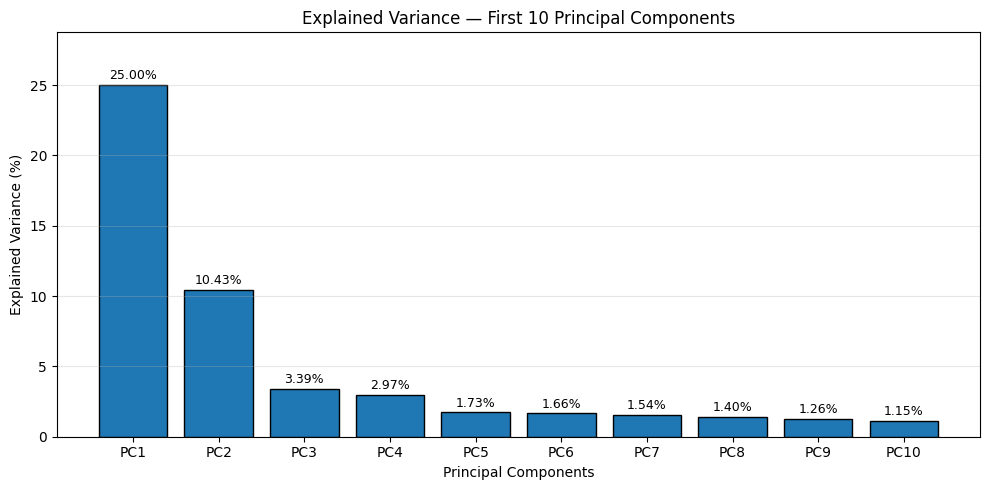

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# Explained variance ratios from Block 08
# The variable 'evr' was calculated previously.

pc_numbers = np.arange(1, 11)
explained_variance = evr[:10] * 100

plt.figure(figsize=(10, 5))

bars = plt.bar(
    pc_numbers,
    explained_variance,
    edgecolor="black"
)

# Display percentages above each bar
for bar, value in zip(bars, explained_variance):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{value:.2f}%",
        ha="center",
        fontsize=9
    )

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance — First 10 Principal Components")

plt.xticks(pc_numbers, [f"PC{i}" for i in pc_numbers])
plt.ylim(0, max(explained_variance) * 1.15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Block 09 — Selecting the Number of Principal Components


BLOCK 09 — PCA COMPONENT SELECTION
90% variance: 142 principal components (actual: 90.0101%)
95% variance: 210 principal components (actual: 95.0506%)
99% variance: 323 principal components (actual: 99.0209%)

DIMENSIONALITY REDUCTION
90% threshold: 16384 -> 142 features; reduction = 99.13%
95% threshold: 16384 -> 210 features; reduction = 98.72%
99% threshold: 16384 -> 323 features; reduction = 98.03%


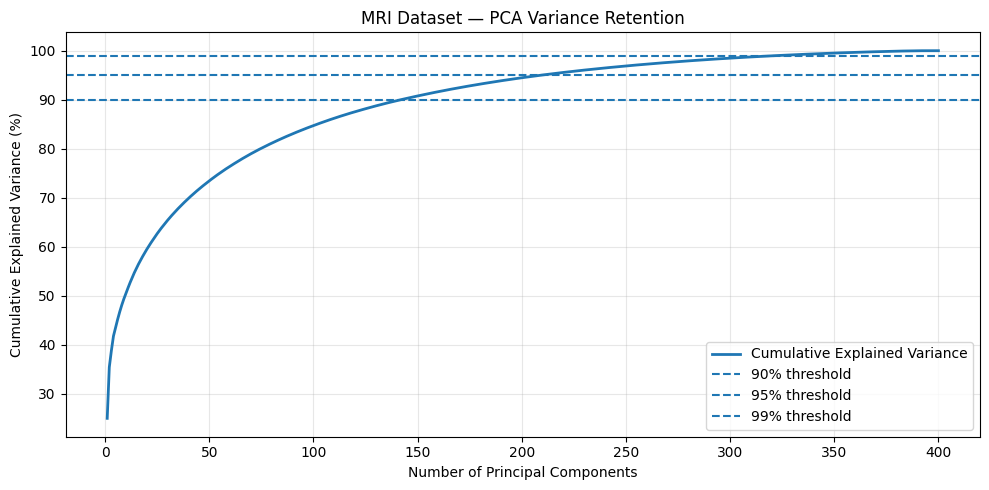


ALL BLOCK 09 CHECKS PASSED: True


In [6]:

import numpy as np
import matplotlib.pyplot as plt

print("BLOCK 09 — PCA COMPONENT SELECTION")

thresholds = [0.90, 0.95, 0.99]
selected_components = {}

for threshold in thresholds:
    k = int(np.searchsorted(cumulative_evr, threshold) + 1)

    selected_components[threshold] = k

    print(
        f"{threshold*100:.0f}% variance: "
        f"{k} principal components "
        f"(actual: {cumulative_evr[k-1]*100:.4f}%)"
    )

print("\nDIMENSIONALITY REDUCTION")

for threshold, k in selected_components.items():
    reduction = (1 - k / X.shape[1]) * 100

    print(
        f"{threshold*100:.0f}% threshold: "
        f"16384 -> {k} features; "
        f"reduction = {reduction:.2f}%"
    )

# Cumulative explained variance graph
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(cumulative_evr) + 1),
    cumulative_evr * 100,
    linewidth=2,
    label="Cumulative Explained Variance"
)

for threshold in thresholds:
    plt.axhline(
        threshold * 100,
        linestyle="--",
        label=f"{threshold*100:.0f}% threshold"
    )

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("MRI Dataset — PCA Variance Retention")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Numerical verification
checks_passed = all(
    cumulative_evr[k-1] >= threshold - 1e-12
    and (k == 1 or cumulative_evr[k-2] < threshold)
    for threshold, k in selected_components.items()
)

print("\nALL BLOCK 09 CHECKS PASSED:", checks_passed)


# ***BLOCK 09 — PCA Component Selection and Dimensionality Reduction***


### BLOCK 09 — PCA Component Selection and Dimensionality Reduction

**Objective:** Determine the minimum number of principal components needed to preserve 90%, 95%, and 99% of the total variance in our MRI dataset.

### 1. Original Data Matrix

Our dataset contains 400 MRI images, each represented by 16,384 pixel features.

$$
X \in \mathbb{R}^{400 \times 16384}
$$

PCA transforms the original features into a smaller number of new numerical features called principal component scores.

$$
Z \in \mathbb{R}^{400 \times k}
$$

Here, k represents the number of retained principal components.

### 2. Cumulative Explained Variance

We calculate the cumulative explained variance:

$$
CEVR(k) = \sum_{i=1}^{k} EVR_i
$$

We select the smallest k satisfying:

$$
CEVR(k) \geq \alpha
$$

where alpha represents the desired variance-retention threshold.

### 3. Numerical Results

| Variance Target | Components (k) | Actual Variance | Feature Reduction |
|---|---:|---:|---:|
| 90% | 142 | 90.0101% | 99.13% |
| 95% | 210 | 95.0506% | 98.72% |
| 99% | 323 | 99.0209% | 98.03% |

For example, retaining 142 principal components transforms our dataset into:

$$
Z \in \mathbb{R}^{400 \times 142}
$$

Each MRI image is now represented by 142 new numerical features instead of 16,384 original pixel values.

**Important:** The 142 components are not images or original pixels. They are new features obtained from linear combinations of the original pixel intensities.

### 4. Graph Interpretation

The cumulative explained variance graph shows:

- X-axis: Number of principal components.
- Y-axis: Percentage of total variance preserved.
- Increasing curve: Cumulative explained variance.
- Horizontal dashed lines: 90%, 95%, and 99% thresholds.

The graph helps identify the smallest number of components required to achieve each threshold.

### 5. Mathematical Conclusion

PCA substantially reduces the dimensionality of our MRI data.

For example, retaining 210 components preserves approximately 95% of the total variance while reducing the feature count by 98.72%.

This does not guarantee that 95% of medically relevant information is preserved.

**Recommendation:** Use 210 components as our initial 95%-variance configuration and compare reconstruction errors for 142, 210, and 323 components in Block 10.


# ***Block 10: PCA Reconstruction Error and Final Verification***

In [7]:

import numpy as np
import matplotlib.pyplot as plt

print("BLOCK 10 — PCA RECONSTRUCTION ERROR")

# Variables from previous blocks:
# X64, Xc, mu, eigenvalues, eigenvectors,
# cumulative_evr, selected_components

# Centered-data Frobenius norm
Xc_norm = np.linalg.norm(Xc, ord="fro")

# Total centered squared energy
total_energy = Xc_norm**2

results = {}

for threshold, k in selected_components.items():

    # First k eigenvectors of the Gram matrix
    U_k = eigenvectors[:, :k]

    # Scores in a coordinate system equivalent to PCA
    singular_values = np.sqrt(
        np.maximum(eigenvalues[:k], 0.0) * (Xc.shape[0] - 1)
    )

    # Reconstruct centered data from the left singular subspace
    Xc_reconstructed = U_k @ (U_k.T @ Xc)

    # Add the mean vector
    X_reconstructed = Xc_reconstructed + mu

    # Relative reconstruction error
    error = np.linalg.norm(
        X64 - X_reconstructed, ord="fro"
    ) / Xc_norm

    # Theoretical PCA error
    theoretical_error = np.sqrt(
        max(0.0, 1.0 - cumulative_evr[k - 1])
    )

    results[threshold] = {
        "k": k,
        "error": error,
        "theoretical_error": theoretical_error,
        "variance": cumulative_evr[k - 1]
    }

    print(f"\nVariance target: {threshold*100:.0f}%")
    print("Components:", k)
    print("Actual variance:", f"{cumulative_evr[k-1]*100:.4f}%")
    print("Reconstruction error:", f"{error:.8f}")
    print("Theoretical error:", f"{theoretical_error:.8f}")

print("\nFINAL VERIFICATION")

errors = [results[t]["error"] for t in selected_components]

checks_passed = (
    all(np.isfinite(errors))
    and all(
        np.isclose(
            results[t]["error"],
            results[t]["theoretical_error"],
            atol=1e-8
        )
        for t in selected_components
    )
    and all(
        errors[i] >= errors[i+1] - 1e-12
        for i in range(len(errors)-1)
    )
)

print("ALL BLOCK 10 CHECKS PASSED:", checks_passed)


BLOCK 10 — PCA RECONSTRUCTION ERROR

Variance target: 90%
Components: 142
Actual variance: 90.0101%
Reconstruction error: 0.31606793
Theoretical error: 0.31606793

Variance target: 95%
Components: 210
Actual variance: 95.0506%
Reconstruction error: 0.22247349
Theoretical error: 0.22247349

Variance target: 99%
Components: 323
Actual variance: 99.0209%
Reconstruction error: 0.09895167
Theoretical error: 0.09895167

FINAL VERIFICATION
ALL BLOCK 10 CHECKS PASSED: True



### BLOCK 10 — Final PCA Results and Conclusions

**Objective:** Evaluate MRI reconstruction accuracy using different numbers of principal components.

The relative reconstruction error is:

$$
E_k = \frac{\|X-\hat{X}_k\|_F}{\|X_c\|_F}
$$

The theoretical relationship is:

$$
E_k = \sqrt{1-CEVR(k)}
$$

**Numerical results:**

| Components | Variance Retained | Reconstruction Error |
|---|---|---|
| 142 | 90.0101% | 0.31606793 |
| 210 | 95.0506% | 0.22247349 |
| 323 | 99.0209% | 0.09895167 |

**Verification:** All numerical reconstruction errors matched their theoretical values to eight decimal places.

ALL BLOCK 10 CHECKS PASSED: True

**Conclusion:** Increasing the number of retained principal components reduces reconstruction error. Using 210 components preserves approximately 95% of the total variance while reducing the number of features per image from 16,384 to 210.

The reconstruction results demonstrate the tradeoff between dimensionality reduction and variance preservation. They do not establish clinical diagnostic performance.
